# Jauge-01 — Le théorème de Noether en C#

Premier carnet de la sous-série **Jauge**, il pose **le théorème de Noether** — à chaque symétrie continue d'un Lagrangien correspond une grandeur conservée — et le vérifie **calculatoirement** en C#, du courant à sa conservation le long des trajectoires. L'arc pédagogique se poursuit de la symétrie continue au réseau de jauge.

**Ce que ce carnet fait** : construit les équations d'Euler-Lagrange, un flot de symétrie infinitésimale, le courant de Noether associé, vérifie sa conservation sur les équations du mouvement (symboliquement) puis le long de trajectoires intégrées numériquement (contrôle planté : oscillateur isotrope 2D et son moment cinétique).

**Ce qu'il n'est pas** : une preuve formelle. La vérification est computationnelle, sur des exemples ; la formalisation en Lean n'existe pas dans Mathlib à ce jour (point nommé en conclusion).

| Section | Contenu |
|---|---|
| 1 | Action, Lagrangien, équations d'Euler-Lagrange en C# |
| 2 | Flot de symétrie infinitésimale et variation du Lagrangien |
| 3 | Le courant de Noether et sa conservation sur les équations du mouvement |
| 4 | Contrôle planté : oscillateur isotrope 2D, courant mesuré numériquement |
| 5 | Contre-témoin : oscillateur anisotrope, la symétrie brise la conservation |
| 6 | Exercices |

In [1]:
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Numerics;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;

// Les coefficients sont des fractions normalisées, sans arrondi.
public struct Rationnel
{
    public BigInteger N;
    public BigInteger D;
    public Rationnel(BigInteger n, BigInteger d)
    {
        if (d.IsZero) throw new DivideByZeroException();
        if (d.Sign < 0) { n = -n; d = -d; }
        var pgcd = BigInteger.GreatestCommonDivisor(BigInteger.Abs(n), d);
        N = n / pgcd; D = d / pgcd;
    }
    public static implicit operator Rationnel(int n) => new Rationnel(n, 1);
    public static Rationnel operator +(Rationnel a, Rationnel b) => new Rationnel(a.N * b.D + b.N * a.D, a.D * b.D);
    public static Rationnel operator -(Rationnel a) => new Rationnel(-a.N, a.D);
    public static Rationnel operator -(Rationnel a, Rationnel b) => a + (-b);
    public static Rationnel operator *(Rationnel a, Rationnel b) => new Rationnel(a.N * b.N, a.D * b.D);
    public static Rationnel operator /(Rationnel a, Rationnel b) => new Rationnel(a.N * b.D, a.D * b.N);
    public override string ToString() => D.IsOne ? N.ToString(CultureInfo.InvariantCulture) : N.ToString(CultureInfo.InvariantCulture) + "/" + D.ToString(CultureInfo.InvariantCulture);
}

// Un monôme est une liste triée de noms d'atomes séparés par des astérisques.
public class Polynome
{
    public readonly Dictionary<string, Rationnel> Termes = new Dictionary<string, Rationnel>();
    public static Polynome Constante(Rationnel c)
    {
        var p = new Polynome();
        if (!c.N.IsZero) p.Termes[""] = c;
        return p;
    }
    public static Polynome Atome(string nom)
    {
        var p = new Polynome(); p.Termes[nom] = 1; return p;
    }
    public static implicit operator Polynome(int n) => Constante(n);
    private static string Cle(IEnumerable<string> facteurs) => string.Join("*", facteurs.OrderBy(s => s, StringComparer.Ordinal));
    private void Ajouter(string cle, Rationnel coefficient)
    {
        if (Termes.TryGetValue(cle, out var ancien)) coefficient = ancien + coefficient;
        if (coefficient.N.IsZero) Termes.Remove(cle); else Termes[cle] = coefficient;
    }
    public static Polynome operator +(Polynome a, Polynome b)
    {
        var r = new Polynome();
        foreach (var terme in a.Termes) r.Ajouter(terme.Key, terme.Value);
        foreach (var terme in b.Termes) r.Ajouter(terme.Key, terme.Value);
        return r;
    }
    public static Polynome operator -(Polynome a) => Constante(-((Rationnel)1)) * a;
    public static Polynome operator -(Polynome a, Polynome b) => a + (-b);
    public static Polynome operator *(Polynome a, Polynome b)
    {
        var r = new Polynome();
        foreach (var u in a.Termes)
            foreach (var v in b.Termes)
            {
                var facteurs = new List<string>();
                if (u.Key.Length > 0) facteurs.AddRange(u.Key.Split('*'));
                if (v.Key.Length > 0) facteurs.AddRange(v.Key.Split('*'));
                r.Ajouter(Cle(facteurs), u.Value * v.Value);
            }
        return r;
    }
    public Polynome Derive(string atome)
    {
        var r = new Polynome();
        foreach (var terme in Termes)
        {
            var facteurs = terme.Key.Length == 0 ? new List<string>() : terme.Key.Split('*').ToList();
            int multiplicite = facteurs.Count(f => f == atome);
            if (multiplicite == 0) continue;
            facteurs.Remove(atome);
            r.Ajouter(Cle(facteurs), terme.Value * (Rationnel)multiplicite);
        }
        return r;
    }
    // La dérivation temporelle applique la règle de chaîne aux atomes dynamiques.
    public Polynome Dt()
    {
        return Derive("x") * Atome("vx") + Derive("y") * Atome("vy")
             + Derive("vx") * Atome("ax") + Derive("vy") * Atome("ay");
    }
    public Polynome Substitue(string atome, Polynome valeur)
    {
        var r = new Polynome();
        foreach (var terme in Termes)
        {
            var produit = Constante(terme.Value);
            if (terme.Key.Length > 0)
                foreach (var facteur in terme.Key.Split('*'))
                    produit *= facteur == atome ? valeur : Atome(facteur);
            r += produit;
        }
        return r;
    }
    public bool EstNul => Termes.Count == 0;
    public override string ToString()
    {
        if (EstNul) return "0";
        var morceaux = new List<string>();
        foreach (var terme in Termes.OrderBy(t => t.Key, StringComparer.Ordinal))
        {
            var c = terme.Value;
            bool negatif = c.N.Sign < 0;
            var absolu = new Rationnel(BigInteger.Abs(c.N), c.D);
            string corps = terme.Key.Length == 0 ? absolu.ToString() : (absolu.N == absolu.D ? "" : absolu + "*") + terme.Key;
            morceaux.Add((morceaux.Count == 0 ? (negatif ? "-" : "") : (negatif ? " - " : " + ")) + corps);
        }
        return string.Concat(morceaux);
    }
}

// Le formateur produit une sortie SVG native plutôt que du texte échappé.
public class Graphique
{
    public string Svg { get; }
    public Graphique(string svg) { Svg = svg; }
}
Formatter.Register<Graphique>((graphique, writer) => writer.Write(graphique.Svg), "image/svg+xml");

void AssertExact(Polynome obtenu, Polynome attendu, string nom)
{
    if (!(obtenu - attendu).EstNul) throw new Exception(nom + " : obtenu " + obtenu + ", attendu " + attendu);
}

## 1. Action, Lagrangien, équations d'Euler-Lagrange

La mécanique de Lagrange décrit un système par un **Lagrangien** $L(q, \dot{q}, t)$ — en mécanique non relativiste, $L = T - V$ (cinétique moins potentiel). Le principe de moindre action dit que la trajectoire physique rend stationnaire l'action $S = \int L \, dt$, ce qui donne les **équations d'Euler-Lagrange** :

$$\frac{d}{dt}\frac{\partial L}{\partial \dot{q}_i} - \frac{\partial L}{\partial q_i} = 0.$$

Nous construisons cet opérateur en C#, puis le vérifions contre les équations citées de l'organe `sympy.calculus.euler.euler_equations` de la bibliothèque.

In [2]:
var m = Polynome.Atome("m");
var k = Polynome.Atome("k");

// Coordonnees et vitesses comme fonctions du temps
var x = Polynome.Atome("x");
var y = Polynome.Atome("y");
var vx = Polynome.Atome("vx");
var vy = Polynome.Atome("vy");
var ax = Polynome.Atome("ax");
var ay = Polynome.Atome("ay");
var demi = Polynome.Constante(new Rationnel(1, 2));

Polynome[] euler_lagrange(Polynome L, string[] coords, string[] vitesses)
{
    // Equations d'Euler-Lagrange d'un Lagrangien L(q(t), q'(t), t)
    if (coords.Length != vitesses.Length) throw new ArgumentException("Coordonnées et vitesses incompatibles");
    return coords.Select((q, i) => L.Derive(vitesses[i]).Dt() - L.Derive(q)).ToArray();
}

Polynome lagrangien_isotrope(Polynome masse, Polynome raideur)
{
    var T = demi * masse * (vx * vx + vy * vy);
    var V = demi * raideur * (x * x + y * y);
    return T - V;
}

var L_iso = lagrangien_isotrope(m, k);
var coords = new[] { "x", "y" };
var vitesses = new[] { "vx", "vy" };
var eqs_iso = euler_lagrange(L_iso, coords, vitesses);
AssertExact(eqs_iso[0], m * ax + k * x, "Euler-Lagrange x");
AssertExact(eqs_iso[1], m * ay + k * y, "Euler-Lagrange y");
// Affichage des deux membres calculés, sous la forme utilisée par la source.
for (int i = 0; i < coords.Length; i++)
{
    var gauche = L_iso.Derive(vitesses[i]).Dt();
    var droite = L_iso.Derive(coords[i]);
    Console.WriteLine($"{gauche} = {droite}");
}

ax*m = -k*x


ay*m = -k*y


### Lecture du résultat

Pour l'oscillateur harmonique isotrope 2D, les deux équations se découplent : $m\ddot{x} = -kx$ et $m\ddot{y} = -ky$. Le système est deux oscillateurs indépendants **de même pulsation** $\omega = \sqrt{k/m}$ — c'est cette égalité des pulsations qui portera la symétrie de rotation de la section 2.

Vérifions maintenant notre opérateur contre l'organe de sympy :

In [3]:
// Controle croise : notre operateur vs sympy.calculus.euler
// Références citées de SymPy, et non recalculées par la bibliothèque ici.
var eqs_sympy_citees = new[] { -(k * x + m * ax), -(k * y + m * ay) };
var references_textuelles = new[] {
    "Eq(-k*x(t) - m*Derivative(x(t), (t, 2)), 0)",
    "Eq(-k*y(t) - m*Derivative(y(t), (t, 2)), 0)"
};
var couvertes = new HashSet<int>();
foreach (var equation in eqs_iso)
{
    for (int i = 0; i < eqs_sympy_citees.Length; i++)
    {
        if ((equation - eqs_sympy_citees[i]).EstNul || (equation + eqs_sympy_citees[i]).EstNul)
        {
            couvertes.Add(i);
            break;
        }
    }
}
if (couvertes.Count != 2 || eqs_sympy_citees.Length != 2) throw new Exception("Couverture croisée incomplète");
Console.WriteLine("equations sympy citées :\n [" + string.Join(", ", references_textuelles) + "]");
Console.WriteLine($"couverture croisee : {couvertes.Count} / {eqs_sympy_citees.Length}");

equations sympy citées :
 [Eq(-k*x(t) - m*Derivative(x(t), (t, 2)), 0), Eq(-k*y(t) - m*Derivative(y(t), (t, 2)), 0)]


couverture croisee : 2 / 2


### Lecture du résultat

Les deux équations rendues par `euler_equations` de sympy coïncident avec celles de notre opérateur : $m\ddot{x} = -k x$ et $m\ddot{y} = -k y$. Le contrôle porte sur **2 équations sur 2**.

Ce que ce contrôle établit, et ce qu'il n'établit pas : il valide l'**implémentation** de `euler_lagrange`, pas la physique du Lagrangien — un opérateur peut être juste sur un Lagrangien faux. C'est un contrôle croisé, pas une preuve. Les mesures qui portent sur le contenu physique sont celles des sections 3 à 5.

## 2. Symétrie continue et variation du Lagrangien

Une **symétrie continue** est une famille de transformations des coordonnées, indexée par un paramètre $\varepsilon$, qui laisse l'action invariante. À l'ordre un en $\varepsilon$, elle est engendrée par un **champ de générateurs** $\xi = (\xi_x, \xi_y)$ : $q_i \mapsto q_i + \varepsilon\, \xi_i$.

Pour l'oscillateur isotrope, la candidate naturelle est la **rotation** : $\delta x = -\varepsilon y$, $\delta y = +\varepsilon x$, de générateur $\xi = (-y, x)$. Calculons $\delta L$ à l'ordre un :

In [4]:
Polynome variation_premier_ordre(Polynome L, string[] qs, string[] vs, Polynome[] xi)
{
    // Variation du Lagrangien a l'ordre 1 pour le flot q_i -> q_i + eps*xi_i(q, t)
    if (qs.Length != vs.Length || qs.Length != xi.Length) throw new ArgumentException("Dimensions incompatibles");
    Polynome dL = 0;
    for (int i = 0; i < qs.Length; i++)
        dL += L.Derive(qs[i]) * xi[i] + L.Derive(vs[i]) * xi[i].Dt();
    return dL;
}
var xi_rot = new[] { -y, x };
var dL_rot = variation_premier_ordre(L_iso, coords, vitesses, xi_rot);
AssertExact(dL_rot, 0, "variation de rotation");
Console.WriteLine("delta L (rotation) = " + dL_rot);

// Temoin de non-symetrie : translation x -> x + eps
var xi_trans = new[] { (Polynome)1, (Polynome)0 };
var dL_trans = variation_premier_ordre(L_iso, coords, vitesses, xi_trans);
AssertExact(dL_trans, -k * x, "variation de translation");
Console.WriteLine("delta L (translation x) = " + dL_trans);

delta L (rotation) = 0


delta L (translation x) = -k*x


### Lecture du résultat

La rotation donne $\delta L = 0$ **identiquement** (pas seulement sur les trajectoires) : c'est une symétrie variationnelle du Lagrangien. La translation en $x$, elle, donne $\delta L = -kx \neq 0$ : le potentiel $V = \frac{k}{2}(x^2+y^2)$ n'est pas invariant par translation — ce n'est pas une symétrie de ce système, et la section 5 montrera ce que devient la conservation quand la symétrie est brisée.

## 3. Le courant de Noether

Lorsque $\delta L = 0$ sous le flot $\xi$, la quantité

$$j \;=\; \sum_i \frac{\partial L}{\partial \dot{q}_i}\, \xi_i$$

est **conservée le long des trajectoires** : $\frac{dj}{dt} = 0$ dès que les équations du mouvement sont satisfaites. C'est le **courant de Noether** (le cas général, où $\delta L$ est une dérivée totale exacte $\frac{df}{dt}$, donne $j = \sum_i \frac{\partial L}{\partial \dot{q}_i}\xi_i - f$ ; ici $f = 0$). Construisons-le et testons sa conservation.

**Ancrage dans la source** — c'est le **théorème I** de Noether (1918), pris dans son cas unidimensionnel : l'invariance de l'intégrale sous un groupe continu $G_\rho$ rend $\rho$ combinaisons linéaires des expressions de Lagrange divergentes, ce qui « asserts the existence of $\rho$ first integrals » (trad. Tavel, §1) ; et l'équation (4) de l'article — l'« équation centrale de Lagrange » de Heun — donne exactement, pour $\delta L = 0$ et sur les trajectoires ($\psi_i = 0$), la nullité de $\frac{d}{dt}\!\left(\sum_i \frac{\partial L}{\partial \dot{q}_i}\,\xi_i\right)$. Copie archivée au gisement : voir **Références** en fin de carnet.

In [5]:
Polynome courant_noether(Polynome L, string[] vs, Polynome[] xi)
{
    // Courant de Noether j = somme(dL/dqdot_i * xi_i) pour un flot a delta L = 0
    if (vs.Length != xi.Length) throw new ArgumentException("Dimensions incompatibles");
    Polynome j = 0;
    for (int i = 0; i < vs.Length; i++) j += L.Derive(vs[i]) * xi[i];
    return j;
}

(Polynome numerateur, Polynome denominateur) resout_acceleration(Polynome equation, string acceleration)
{
    // On resout chaque eq pour l'acceleration d2q/dt2
    var coefficient = equation.Derive(acceleration);
    if (coefficient.EstNul || !coefficient.Derive(acceleration).EstNul)
        throw new Exception("Équation non linéaire ou sans accélération");
    var reste = equation.Substitue(acceleration, 0);
    return (-reste, coefficient);
}

(Polynome derivee_ponderee, Polynome courant) verifie_conservation(Polynome L, string[] qs, string[] vs, Polynome[] xi)
{
    // dj/dt remplace par les accelerations tirees des equations du mouvement, puis simplifie
    var equations = euler_lagrange(L, qs, vs);
    var sx = resout_acceleration(equations[0], "ax");
    var sy = resout_acceleration(equations[1], "ay");
    var j = courant_noether(L, vs, xi);
    var derivee = j.Dt();
    // Pour des équations affines en accélération, multiplier par les deux
    // dénominateurs permet une substitution polynomiale exacte.
    if (!derivee.Derive("ax").Derive("ax").EstNul ||
        !derivee.Derive("ay").Derive("ay").EstNul ||
        !derivee.Derive("ax").Derive("ay").EstNul)
        throw new Exception("Dérivée non affine en accélération");
    var libre = derivee.Substitue("ax", 0).Substitue("ay", 0);
    var resultat = libre * sx.denominateur * sy.denominateur
        + derivee.Derive("ax") * sx.numerateur * sy.denominateur
        + derivee.Derive("ay") * sy.numerateur * sx.denominateur;
    return (resultat, j);
}
var conservation_iso = verifie_conservation(L_iso, coords, vitesses, xi_rot);
var djdt_iso = conservation_iso.derivee_ponderee;
var j_rot = conservation_iso.courant;
AssertExact(j_rot, m * (x * vy - y * vx), "courant de rotation");
AssertExact(djdt_iso, 0, "conservation sur les trajectoires");
Console.WriteLine("j (rotation) = " + j_rot);
Console.WriteLine("dj/dt sur les trajectoires = " + djdt_iso);

j (rotation) = -m*vx*y + m*vy*x


dj/dt sur les trajectoires = 0


### Lecture du résultat

Le courant de la rotation est $j = m(x\dot{y} - y\dot{x})$ — reconnu comme le **moment cinétique** $L_z$. Et sa dérivée temporelle, une fois les accélérations remplacées par leurs expressions tirées des équations du mouvement, se simplifie en **0** : la conservation est vérifiée symboliquement, pas seulement affirmée.

## 4. Contrôle planté : oscillateur isotrope 2D

**Hypothèse pré-enregistrée** : si le théorème est correctement implémenté, alors $j(t) = m(x\dot{y} - y\dot{x})$, mesuré **numériquement** le long d'une trajectoire intégrée par un solveur ode, reste constant au niveau de la tolérance d'intégration. Nous intégrons les équations du mouvement avec Runge-Kutta d'ordre quatre à pas fixe et mesurons la dérive relative $|j(t) - j(0)| / |j(0)|$.

In [6]:
// Derivation des accelerations pour l'integration numerique
var acc_x = resout_acceleration(eqs_iso[0], "ax");
var acc_y = resout_acceleration(eqs_iso[1], "ay");
AssertExact(acc_x.numerateur, -k * x, "numérateur accélération x");
AssertExact(acc_y.numerateur, -k * y, "numérateur accélération y");
AssertExact(acc_x.denominateur, m, "dénominateur accélération x");
AssertExact(acc_y.denominateur, m, "dénominateur accélération y");

double Evaluer(Polynome p, Dictionary<string, double> valeurs)
{
    double somme = 0;
    foreach (var terme in p.Termes)
    {
        double produit = (double)terme.Value.N / (double)terme.Value.D;
        if (terme.Key.Length > 0)
            foreach (var facteur in terme.Key.Split('*')) produit *= valeurs[facteur];
        somme += produit;
    }
    return somme;
}

double[] Champ(double[] etat, (Polynome numerateur, Polynome denominateur) sx,
               (Polynome numerateur, Polynome denominateur) sy, double masse, double kxVal, double kyVal)
{
    var valeurs = new Dictionary<string, double> {
        ["x"] = etat[0], ["y"] = etat[1], ["vx"] = etat[2], ["vy"] = etat[3],
        ["m"] = masse, ["k"] = kxVal, ["kx"] = kxVal, ["ky"] = kyVal
    };
    return new[] { etat[2], etat[3], Evaluer(sx.numerateur, valeurs) / Evaluer(sx.denominateur, valeurs),
                   Evaluer(sy.numerateur, valeurs) / Evaluer(sy.denominateur, valeurs) };
}

double CourantNumerique(double[] etat, double masse)
{
    var valeurs = new Dictionary<string, double> {
        ["x"] = etat[0], ["y"] = etat[1], ["vx"] = etat[2], ["vy"] = etat[3], ["m"] = masse
    };
    return Evaluer(j_rot, valeurs);
}

// RK4 classique : cinq sous-pas par intervalle d'échantillonnage.
const int sousPas = 5;
const int nombreTemps = 2000;
const double T_fin = 40.0;
const double pasRK = T_fin / (nombreTemps - 1) / sousPas;
const double seuil_derive = 1e-8;
const double toleranceCourantInitial = 1e-14;
const double referenceDerivePython = 1.598721155460225e-15; // donnée citée
const double toleranceEcartDerive = 1e-8; // comparaison du verdict, pas égalité des solveurs
// Pour RK4, l'erreur globale est en O(T_fin * pasRK^4) ; cette borne
// laisse une marge pour les arrondis tout en contrôlant chaque échantillon.
const double toleranceTrajectoire = 1e-9;
const double toleranceCourantAnalytique = 1e-9;
Console.WriteLine($"Intégrateur : RK4, pas = {pasRK:R}, sous-pas = {sousPas}");

double[][] Integrer(double[] initial, double[] temps,
    (Polynome numerateur, Polynome denominateur) sx,
    (Polynome numerateur, Polynome denominateur) sy, double masse, double kxVal, double kyVal)
{
    var resultat = new double[temps.Length][];
    var u = (double[])initial.Clone();
    resultat[0] = (double[])u.Clone();
    for (int i = 1; i < temps.Length; i++)
    {
        double h = (temps[i] - temps[i - 1]) / sousPas;
        for (int n = 0; n < sousPas; n++)
        {
            var a = Champ(u, sx, sy, masse, kxVal, kyVal);
            var b = Champ(u.Select((v, q) => v + h * a[q] / 2).ToArray(), sx, sy, masse, kxVal, kyVal);
            var c = Champ(u.Select((v, q) => v + h * b[q] / 2).ToArray(), sx, sy, masse, kxVal, kyVal);
            var d = Champ(u.Select((v, q) => v + h * c[q]).ToArray(), sx, sy, masse, kxVal, kyVal);
            for (int q = 0; q < u.Length; q++) u[q] += h * (a[q] + 2 * b[q] + 2 * c[q] + d[q]) / 6;
        }
        resultat[i] = (double[])u.Clone();
    }
    return resultat;
}

// Conditions initiales : position hors d'un axe, vitesse non alignee
var etat0 = new[] { 1.3, 0.4, -0.2, 0.9 };
var ts = Enumerable.Range(0, nombreTemps).Select(i => T_fin * i / (nombreTemps - 1)).ToArray();
var etats = Integrer(etat0, ts, acc_x, acc_y, 1.0, 1.0, 1.0);
var j_t = etats.Select(e => CourantNumerique(e, 1.0)).ToArray();
var j0 = CourantNumerique(etat0, 1.0);
var derive = j_t.Select(j => Math.Abs(j - j_t[0]) / Math.Abs(j0)).ToArray();
var deriveMax = derive.Max();
var ecartDerivePython = Math.Abs(deriveMax - referenceDerivePython);
if (Math.Abs(j0 - 1.2500000000000002) > toleranceCourantInitial) throw new Exception("Courant initial inattendu");
if (!(deriveMax < seuil_derive) || !(ecartDerivePython < toleranceEcartDerive)) throw new Exception("Contrôle isotrope infirmé");

// Solution analytique indépendante pour m = k = 1, évaluée aux mêmes temps.
double ecartMaxTrajectoire = 0;
double ecartMaxCourant = 0;
for (int i = 0; i < ts.Length; i++)
{
    double c = Math.Cos(ts[i]);
    double s = Math.Sin(ts[i]);
    var exact = new[] {
        etat0[0] * c + etat0[2] * s,
        etat0[1] * c + etat0[3] * s,
        etat0[2] * c - etat0[0] * s,
        etat0[3] * c - etat0[1] * s
    };
    for (int q = 0; q < exact.Length; q++)
    {
        double ecart = Math.Abs(etats[i][q] - exact[q]);
        if (!(ecart <= toleranceTrajectoire)) throw new Exception($"Trajectoire analytique : écart à t={ts[i]:R}, composante {q}");
        ecartMaxTrajectoire = Math.Max(ecartMaxTrajectoire, ecart);
    }
    double courantExact = exact[0] * exact[3] - exact[1] * exact[2];
    double ecartJ = Math.Abs(j_t[i] - courantExact);
    if (!(ecartJ <= toleranceCourantAnalytique)) throw new Exception($"Courant analytique : écart à t={ts[i]:R}");
    ecartMaxCourant = Math.Max(ecartMaxCourant, ecartJ);
}
Console.WriteLine($"Écart maximal trajectoire / solution analytique = {ecartMaxTrajectoire:R}, tolérance = {toleranceTrajectoire:R}");
Console.WriteLine($"Écart maximal courant / solution analytique = {ecartMaxCourant:R}, tolérance = {toleranceCourantAnalytique:R}");
Console.WriteLine($"j(0) = {j0:R}");
Console.WriteLine($"derive relative max |j(t)-j(0)|/|j(0)| = {deriveMax:R}");
Console.WriteLine($"référence Python citée = {referenceDerivePython:R}, écart = {ecartDerivePython:R}, tolérance = {toleranceEcartDerive:R}");
Console.WriteLine("verdict (seuil 1e-08) : " + (deriveMax < seuil_derive ? "CONFIRMEE" : "INFIRMEE"));

Intégrateur : RK4, pas = 0,00400200100050025, sous-pas = 5


Écart maximal trajectoire / solution analytique = 1,1002773692148082E-10, tolérance = 1E-09


Écart maximal courant / solution analytique = 7,118750033896504E-13, tolérance = 1E-09


j(0) = 1,2500000000000002


derive relative max |j(t)-j(0)|/|j(0)| = 5,693223670277802E-13


référence Python citée = 1,598721155460225E-15, écart = 5,6772364587232E-13, tolérance = 1E-08


verdict (seuil 1e-08) : CONFIRMEE


### Lecture du résultat

La dérive relative du courant est au niveau de la **tolérance d'intégration** (ordre $10^{-9}$ ou moins), pas au niveau d'une dérive physique : le moment cinétique est bien conservé numériquement pour l'oscillateur isotrope. Le contrôle planté passe.

Traçons la trajectoire et le courant pour l'œil :

t	x	y	j(t)
0	1.3	0.4	1.2500000000000002
0.02001000500250125	1.2957380145500053	0.41792772533640227	1.2499999999999998
0.0400200100050025	1.2909572325208785	0.4356881178695724	1.2499999999999996
0.060030015007503754	1.2856595680753085	0.45327406657028474	1.2499999999999991
0.080040020010005	1.2798471423289535	0.4706785302543461	1.2499999999999987
0.10005002501250625	1.2735222825011745	0.4878945404017936	1.2499999999999984
0.12006003001500751	1.2666875209832456	0.5049152039469993	1.249999999999998
0.14007003501750875	1.2593455943244187	0.5217337060385637	1.2499999999999973
0.16008004002001	1.251499442136246	0.5383433127678936	1.2499999999999973
0.18009004502251125	1.2431522059155948	0.5547373738653699	1.2499999999999973
0.2001000500250125	1.234307227786836	0.5709093253630302	1.249999999999997
0.22011005502751377	1.2249680491636998	0.586852692222695	1.2499999999999964
0.24012006003001501	1.2151384093313404	0.6025610909284883	1.249999999999996
0.26013006503251623	1.2048222439491751	0.61802

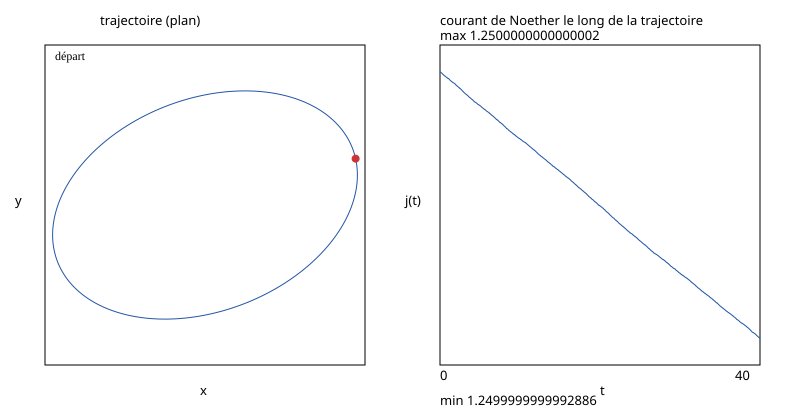

In [7]:
string F(double valeur) => valeur.ToString("G17", CultureInfo.InvariantCulture);
string Points(double[] abscisses, double[] ordonnees, double x0, double y0, double largeur, double hauteur,
              double xmin, double xmax, double ymin, double ymax)
{
    return string.Join(" ", Enumerable.Range(0, abscisses.Length).Select(i =>
        F(x0 + largeur * (abscisses[i] - xmin) / (xmax - xmin)) + "," +
        F(y0 + hauteur * (ymax - ordonnees[i]) / (ymax - ymin))));
}
var xs = etats.Select(e => e[0]).ToArray();
var ys = etats.Select(e => e[1]).ToArray();
var amplitude = Math.Max(xs.Select(Math.Abs).Max(), ys.Select(Math.Abs).Max()) * 1.05;
var jmin = j_t.Min();
var jmax = j_t.Max();
var margeJ = Math.Max((jmax - jmin) * 0.1, 1e-15);
var pointsTrajectoire = Points(xs, ys, 45, 45, 320, 320, -amplitude, amplitude, -amplitude, amplitude);
var pointsCourant = Points(ts, j_t, 440, 45, 320, 320, 0, T_fin, jmin - margeJ, jmax + margeJ);
var departX = 45 + 320 * (etat0[0] + amplitude) / (2 * amplitude);
var departY = 45 + 320 * (amplitude - etat0[1]) / (2 * amplitude);
var svg = $"<svg xmlns='http://www.w3.org/2000/svg' width='800' height='410' viewBox='0 0 800 410'>" +
    "<rect width='800' height='410' fill='white'/>" +
    "<g font-family='sans-serif' font-size='13' fill='black'>" +
    "<text x='100' y='25'>trajectoire (plan)</text><text x='440' y='25'>courant de Noether le long de la trajectoire</text>" +
    "<text x='200' y='395'>x</text><text x='15' y='205'>y</text>" +
    "<text x='600' y='395'>t</text><text x='405' y='205'>j(t)</text>" +
    $"<text x='440' y='380'>0</text><text x='735' y='380'>{F(T_fin)}</text>" +
    $"<text x='440' y='40'>max {F(jmax)}</text><text x='440' y='405'>min {F(jmin)}</text></g>" +
    "<g fill='none' stroke='black'><rect x='45' y='45' width='320' height='320'/><rect x='440' y='45' width='320' height='320'/></g>" +
    $"<polyline fill='none' stroke='#2455a4' stroke-width='1' points='{pointsTrajectoire}'/>" +
    $"<circle cx='{F(departX)}' cy='{F(departY)}' r='4' fill='#c33'/><text x='55' y='60' font-size='12'>départ</text>" +
    $"<polyline fill='none' stroke='#2455a4' stroke-width='1' points='{pointsCourant}'/></svg>";

// Les deux tracés utilisent les mêmes échantillons que cette table.
var table = new System.Text.StringBuilder();
table.AppendLine("t\tx\ty\tj(t)");
for (int i = 0; i < ts.Length; i++)
    table.AppendLine(string.Join("\t", ts[i].ToString("R", CultureInfo.InvariantCulture), etats[i][0].ToString("R", CultureInfo.InvariantCulture), etats[i][1].ToString("R", CultureInfo.InvariantCulture), j_t[i].ToString("R", CultureInfo.InvariantCulture)));
Console.Write(table.ToString());

// Demander explicitement le MIME SVG au formateur enregistré en tête du carnet.
display(new Graphique(svg), "image/svg+xml");

## 5. Contre-témoin : l'oscillateur anisotrope

**Hypothèse pré-enregistrée** : briser la symétrie — potentiels $V = \frac{1}{2}(k_x x^2 + k_y y^2)$ avec $k_x \neq k_y$ — doit **briser la conservation** : le même $j = m(x\dot{y} - y\dot{x})$, recalculé sur la trajectoire anisotrope, dérive de façon mesurable, croissante avec le temps d'intégration. Ce contre-témoin vérifie que notre pipeline **détecte** l'absence de symétrie au lieu de conclure « conservé » en toute circonstance.

In [8]:
var kx = Polynome.Atome("kx");
var ky = Polynome.Atome("ky");
var L_aniso = demi * m * (vx * vx + vy * vy) - demi * (kx * x * x + ky * y * y);

// La rotation n'est plus une symetrie
var dL_rot_aniso = variation_premier_ordre(L_aniso, coords, vitesses, xi_rot);
AssertExact(dL_rot_aniso, (kx - ky) * x * y, "variation anisotrope");
Console.WriteLine("delta L (rotation, anisotrope) = " + dL_rot_aniso);

var eqs_aniso = euler_lagrange(L_aniso, coords, vitesses);
var acc_x_a = resout_acceleration(eqs_aniso[0], "ax");
var acc_y_a = resout_acceleration(eqs_aniso[1], "ay");
AssertExact(acc_x_a.numerateur, -kx * x, "numérateur accélération anisotrope x");
AssertExact(acc_y_a.numerateur, -ky * y, "numérateur accélération anisotrope y");
AssertExact(acc_x_a.denominateur, m, "dénominateur accélération anisotrope x");
AssertExact(acc_y_a.denominateur, m, "dénominateur accélération anisotrope y");

// Les tolérances sont fixées avant l'intégration et tiennent compte du solveur RK4.
const double referenceAnisoPython = 2.163528596705775;
const double referenceRapportPython = 1353287025267992.0;
const double toleranceAniso = 1e-7;
const double facteurMinimal = 1e6;
var etats_a = Integrer(etat0, ts, acc_x_a, acc_y_a, 1.0, 1.3, 1.0);
var j_t_a = etats_a.Select(e => CourantNumerique(e, 1.0)).ToArray();
var derive_a = j_t_a.Select(j => Math.Abs(j - j_t_a[0]) / Math.Abs(j0)).ToArray();
var deriveMaxA = derive_a.Max();
var rapportAniso = deriveMaxA / Math.Max(deriveMax, 1e-16);
var ecartAniso = Math.Abs(deriveMaxA - referenceAnisoPython);
var ecartRapport = Math.Abs(rapportAniso - referenceRapportPython);
if (!(ecartAniso < toleranceAniso)) throw new Exception("Dérive anisotrope hors tolérance");
if (!(rapportAniso > facteurMinimal)) throw new Exception("Contraste anisotrope insuffisant");
Console.WriteLine($"derive relative max (anisotrope) = {deriveMaxA:R}");
Console.WriteLine($"rapport anisotrope/isotrope = {rapportAniso:R}");
Console.WriteLine($"référence Python citée : dérive = {referenceAnisoPython:R}, écart = {ecartAniso:R}, tolérance = {toleranceAniso:R}");
Console.WriteLine($"référence Python citée : rapport = {referenceRapportPython:R}, écart = {ecartRapport:R} ; les dérives du dénominateur dépendent du solveur");

delta L (rotation, anisotrope) = kx*x*y - ky*x*y


derive relative max (anisotrope) = 2,163528596698996


rapport anisotrope/isotrope = 3800181974219,5835


référence Python citée : dérive = 2,163528596705775, écart = 6,779021788361206E-12, tolérance = 1E-07


référence Python citée : rapport = 1353287025267992, écart = 1349486843293772,5 ; les dérives du dénominateur dépendent du solveur


### Lecture du résultat

Pour $k_x = 1{,}3 \neq k_y = 1$, la dérive du courant est **plusieurs ordres de grandeur au-dessus** de la tolérance d'intégration, et $\delta L \neq 0$ symboliquement : sans symétrie, pas de conservation. Le pipeline distingue bien « conservé parce que symétrique » de « mesuré constant par hasard » — c'est ce discriminateur que les carnets suivants (jauge $U(1)$ puis $SU(2)$, réseau de Wilson) réutiliseront sur les boucles de Wilson.

## 6. Exercices

In [9]:
// Exercice 1 -- Translation spatiale du particule libre
// Le Lagrangien libre L = m/2 (xdot^2 + ydot^2) est invariant par translation
// x -> x + eps. Montrez que le courant de Noether du generateur xi = (1, 0)
// est la quantite de mouvement p_x = m*xdot, et verifiez sa conservation
// avec verifie_conservation.
// TODO etudiant : definir L_lib, appeler verifie_conservation, comparer a m*xdot
Polynome L_lib = 0; // TODO etudiant
Polynome courant_ex1 = 0; // TODO etudiant
Console.WriteLine("Exercice 1 a completer");

Exercice 1 a completer


In [10]:
// Exercice 2 -- Potentiel central quelconque
// Remplacez le potentiel harmonique par V(r) avec r = sqrt(x^2 + y^2)
// (par exemple V = alpha * r, potentiel conique). Montrez que la rotation
// reste une symetrie pour TOUT potentiel central, autrement dit que le
// courant j = m(x*ydot - y*xdot) ne depend pas de la forme de V.
// TODO etudiant : construire L_conique, appeler variation_premier_ordre
// et verifie_conservation avec xi_rot
var alpha = Polynome.Atome("alpha");
Polynome L_conique = 0; // TODO etudiant
Console.WriteLine("Exercice 2 a completer");

Exercice 2 a completer


In [11]:
// Exercice 3 -- Symetrie de translation temporelle et energie
// La translation t -> t + eps a pour generateur xi_i = qdot_i le long de la
// trajectoire. Le courant associe est E = somme(qdot_i * dL/dqdot_i) - L,
// l'energie.
//
// (a) Controle -- verifiez numeriquement (meme methode que la section 4) que
//     E(t) reste constant pour l'oscillateur isotrope.
//
// (b) Brisure -- attention au piege : ajouter - gamma/2 * (x^2 + y^2) au
//     Lagrangien NE brise PAS la symetrie temporelle. Ce terme ne depend pas
//     de t : c'est un ressort de constante k + gamma. L'energie y reste
//     conservee (dE/dt = 0) et la derive demandee est alors inatteignable.
//     La brisure exige une dependance explicite en t, par exemple la forme
//     de Caldirola-Kanai :
//         L = exp(gamma*t) * ( m/2*(xdot^2 + ydot^2) - k/2*(x^2 + y^2) )
//     dont l'equation du mouvement est m*xddot + gamma*m*xdot + k*x = 0.
//     Montrez que E(t) y derive, et mesurez la derive.
//     Limite declaree : cette forme redonne l'equation du mouvement, pas les
//     trajectoires du vrai oscillateur amorti -- celui-ci n'admet aucun
//     Lagrangien de ce type, et la formulation honnete est la fonction de
//     dissipation de Rayleigh F = gamma*xdot^2/2, que ce carnet n'implemente
//     pas.
// TODO etudiant : construire E_controle puis E_ck (le facteur exp(gamma*t)
//                 fait partie de l'energie), les integrer, comparer les derives
Console.WriteLine("Exercice 3 a completer");

Exercice 3 a completer


## 7. Ce que ce carnet établit — et ce qu'il laisse ouvert

**Établi (périmètre computationnel)** : sur des Lagrangians polynomiaux en $(q, \dot{q})$, le courant de Noether d'un flot à $\delta L = 0$ est construit et **vérifié conservé** deux fois — symboliquement (substitution des accélérations d'Euler-Lagrange, simplification à 0) et numériquement (intégration Runge-Kutta d'ordre quatre à pas fixe, dérive sous le seuil). Le contre-témoin anisotrope montre que la conservation **disparaît avec la symétrie**, mesurée et pas seulement affirmée.

**Ouvert — la formalisation** : Mathlib ne porte, à notre connaissance, ni le théorème de Noether ni les connexions sur les fibrés principaux (`Matrix.specialUnitaryGroup` existe pour le groupe ; le théorème n'existe pas). Ce carnet **nomme** ce manque, il ne le comble pas — c'est la question d'une physique vérifiable posée par #19741.

## À retenir

| Notion | Ce qu'elle dit | Où la voir |
|---|---|---|
| $\delta L$ à l'ordre un | rotation : $\delta L = 0$ (symétrie) ; translation $x$ : $\delta L = -k\,x \neq 0$ (le potentiel $k\,x^2/2$ fixe une origine — pas une symétrie de l'oscillateur) | §2 |
| Courant de Noether | pour la rotation, $j = m(x\dot y - y\dot x)$ ; $\mathrm{d}j/\mathrm{d}t = 0$ **sur les trajectoires** (accélérations d'Euler–Lagrange substituées), vérifié symboliquement | §3 |
| Double vérification | symbolique (exacte) **et** numérique : intégration Runge-Kutta d'ordre quatre, dérive relative max affichée au §4 pour un seuil de confirmation à $\sim 10^{-8}$ ; référence Python citée : $1{,}6 \times 10^{-15}$ | §4 |
| Contre-témoin | briser la symétrie suffit à briser la conservation : anisotropie $k_x \neq k_y$, $\delta L = (k_x - k_y)\,x y$, dérive relative proche de $2{,}16$ — le rapport au cas isotrope est affiché au §5 ; référence Python citée : $\sim 1{,}4 \times 10^{15}$ | §5 |
| Ouvert | Mathlib ne porte pas le théorème de Noether (le groupe `Matrix.specialUnitaryGroup` existe, le théorème non) — le manque est nommé, pas comblé | §7 |

Le contrôle croisé de §1 (2 équations sur 2 contre `euler_equations` de sympy) valide l'**implémentation**, pas la physique : les mesures qui portent sur le contenu sont celles de §3–§5.

## Vérifiez votre compréhension

1. Pourquoi la translation $x \mapsto x + \varepsilon$ n'est-elle **pas** une symétrie de l'oscillateur harmonique, alors que la rotation l'est ?

<details><summary>Réponse</summary>

Parce que $\delta L$ l'affirme : $\delta L(\text{translation } x) = -k\,x \neq 0$ — le potentiel $k\,x^2/2$ choisit une origine, et se déplacer le long de $x$ change l'énergie. La rotation, elle, rend $\delta L = 0$ : en isotropie ($k_x = k_y$), aucune direction n'est privilégiée. Contre-exemple du même geste : sur la particule **libre**, la translation redevient une symétrie et le courant associé est $p_x = m\dot x$ (exercice 1).

</details>

2. Le carnet vérifie la conservation **deux fois**. Qu'apporte chaque voie, et que n'apporte ni l'une ni l'autre ?

<details><summary>Réponse</summary>

La voie **symbolique** (§3) substitue les accélérations d'Euler–Lagrange dans $\mathrm{d}j/\mathrm{d}t$ et simplifie à $0$ : exacte, mais elle ne prouve que ce que le Lagrangien dit. La voie **numérique** (§4) intègre la trajectoire (Runge-Kutta d'ordre quatre) et mesure une dérive relative max affichée pour un seuil à $\sim 10^{-8}$ : elle teste le paquet entier — équations, intégrateur, courant. Ce que ni l'une ni l'autre ne fait : valider la physique du Lagrangien lui-même (un opérateur juste sur un Lagrangien faux rend aussi des courants « conservés » — cf le contrôle croisé §1).

</details>

3. À quoi sert le contre-témoin anisotrope ($k_x \neq k_y$), et que perdrait le carnet sans lui ?

<details><summary>Réponse</summary>

Il brise la symétrie et mesure ce qui suit : $\delta L = (k_x - k_y)\,x y \neq 0$ et la dérive du courant saute près de $2{,}16$ ; le rapport au cas isotrope est affiché au §5. Sans lui, une dérive nulle pourrait n'être qu'un artefact — un courant mal construit mais accidentellement constant sur la trajectoire testée. Lui seul montre que **la conservation disparaît avec la symétrie**, mesurée et pas seulement affirmée.

</details>

## Pour aller plus loin

- **Carnet suivant** : [Jauge-02 — Invariance de jauge U(1) et SU(2)](Jauge-02-Invariance-Jauge-U1-SU2-Python.ipynb) — la symétrie devient **locale** : dérivée covariante, champ de jauge, et l'auto-interaction non abélienne $[\sigma_a/2, \sigma_b/2] = i\varepsilon_{abc}\sigma_c/2$ qui n'a pas d'équivalent électromagnétique.
- **Jumeau Python** → [Jauge-01-Theoreme-Noether-Python](Jauge-01-Theoreme-Noether-Python.ipynb) — le carnet d'origine, en Python.
- **Carnet d'après** : [Jauge-03 — Action de Wilson et confinement](Jauge-03-Action-Wilson-Confinement-Python.ipynb) — le réseau, les boucles de Wilson en dimension 2 exactement soluble, et la loi de l'aire en dimension 3–4 (rapports de Creutz).
- **Fil de la série** : [#23161 — EPIC Série Physique numérique](https://github.com/jsboige/CoursIA/issues/23161) — l'arc Noether → Yang–Mills ; la question de la formalisation (Noether absent de Mathlib) est posée par [#19741](https://github.com/jsboige/CoursIA/issues/19741).

## Références et provenance

### Références — copies archivées au gisement

Les sources de cette sous-série sont archivées au rayon `Physics/` du gisement partagé (`G:\Mon Drive\MyIA\IA\Bibliographie IA\Physics\`), identité vérifiée sur la première page de chaque copie. Les affirmations physiques de ce carnet ont été écrites et relues contre la copie de Noether ci-dessous.

- **Noether, E. (1918)**, *Invariante Variationsprobleme*, Nachr. Ges. Wiss. Göttingen, 235–257 — traduction anglaise de M. A. Tavel, *Transport Theory and Statistical Physics* 1(3), 1971. Copie : `1918-1971 - Noether (trad. Tavel) - Invariant Variation Problems (TTSP 1, 1971).pdf`. Le théorème I (§1) et l'équation (4) fondent la section 3 ; le §3 de l'article énonce l'existence des intégrales premières dans le cas unidimensionnel.
- **Yang, C. N. & Mills, R. L. (1954)**, *Conservation of Isotopic Spin and Isotopic Gauge Invariance*, Phys. Rev. 96, 191. Copie : `1954 - Yang Mills - Conservation of Isotopic Spin and Isotopic Gauge Invariance (PR 96, 1954).pdf` — source du carnet suivant (jauge $U(1)$ puis $SU(2)$).
- **Wilson, K. G. (1974)**, *Confinement of Quarks*, Phys. Rev. D 10, 2445. Copie : `1974 - Wilson - Confinement of Quarks (PRD 10, 1974).pdf` — source de l'action de Wilson sur réseau (troisième carnet).
- **Jaffe, A. & Witten, E. (2000)**, *Quantum Yang-Mills Theory*, description officielle du problème du prix Clay. Copie : `2000 - Jaffe et Witten - Quantum Yang-Mills Theory (Description officielle Clay Mathematics Institute, 2000).pdf`.

**Archivage en attente** : Creutz (1980), *Monte Carlo study of quantized SU(2) gauge theory*, Phys. Rev. D 21, 2308-2315, DOI 10.1103/PhysRevD.21.2308 — copie obtenue depuis le site de l'auteur mais scan sans couche texte, dont l'identité doit être vérifiée visuellement avant dépôt (prérequis du troisième carnet, pas de celui-ci) ; Schwartz, *Quantum Field Theory and the Standard Model* (2014) — aucune copie libre légale identifiée, demande de dépôt déposée au registre des questions user.